In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio2_primos_omp.csv')
df

,schedule,threads,tiempo_s,speedup,eficiencia_pct,primos
0,static,1,1.453032,1.0000,100.00,664579
1,static,2,0.968053,1.5010,75.05,664579
2,static,4,0.560949,2.5903,64.76,664579
3,static,8,0.357701,4.0621,50.78,664579
4,static,16,0.242547,5.9907,37.44,664579
5,dynamic,1,1.453032,1.0000,100.00,664579
6,dynamic,2,0.780027,1.8628,93.14,664579
7,dynamic,4,0.462869,3.1392,78.48,664579
8,dynamic,8,0.274284,5.2975,66.22,664579
9,dynamic,16,0.199856,7.2704,45.44,664579


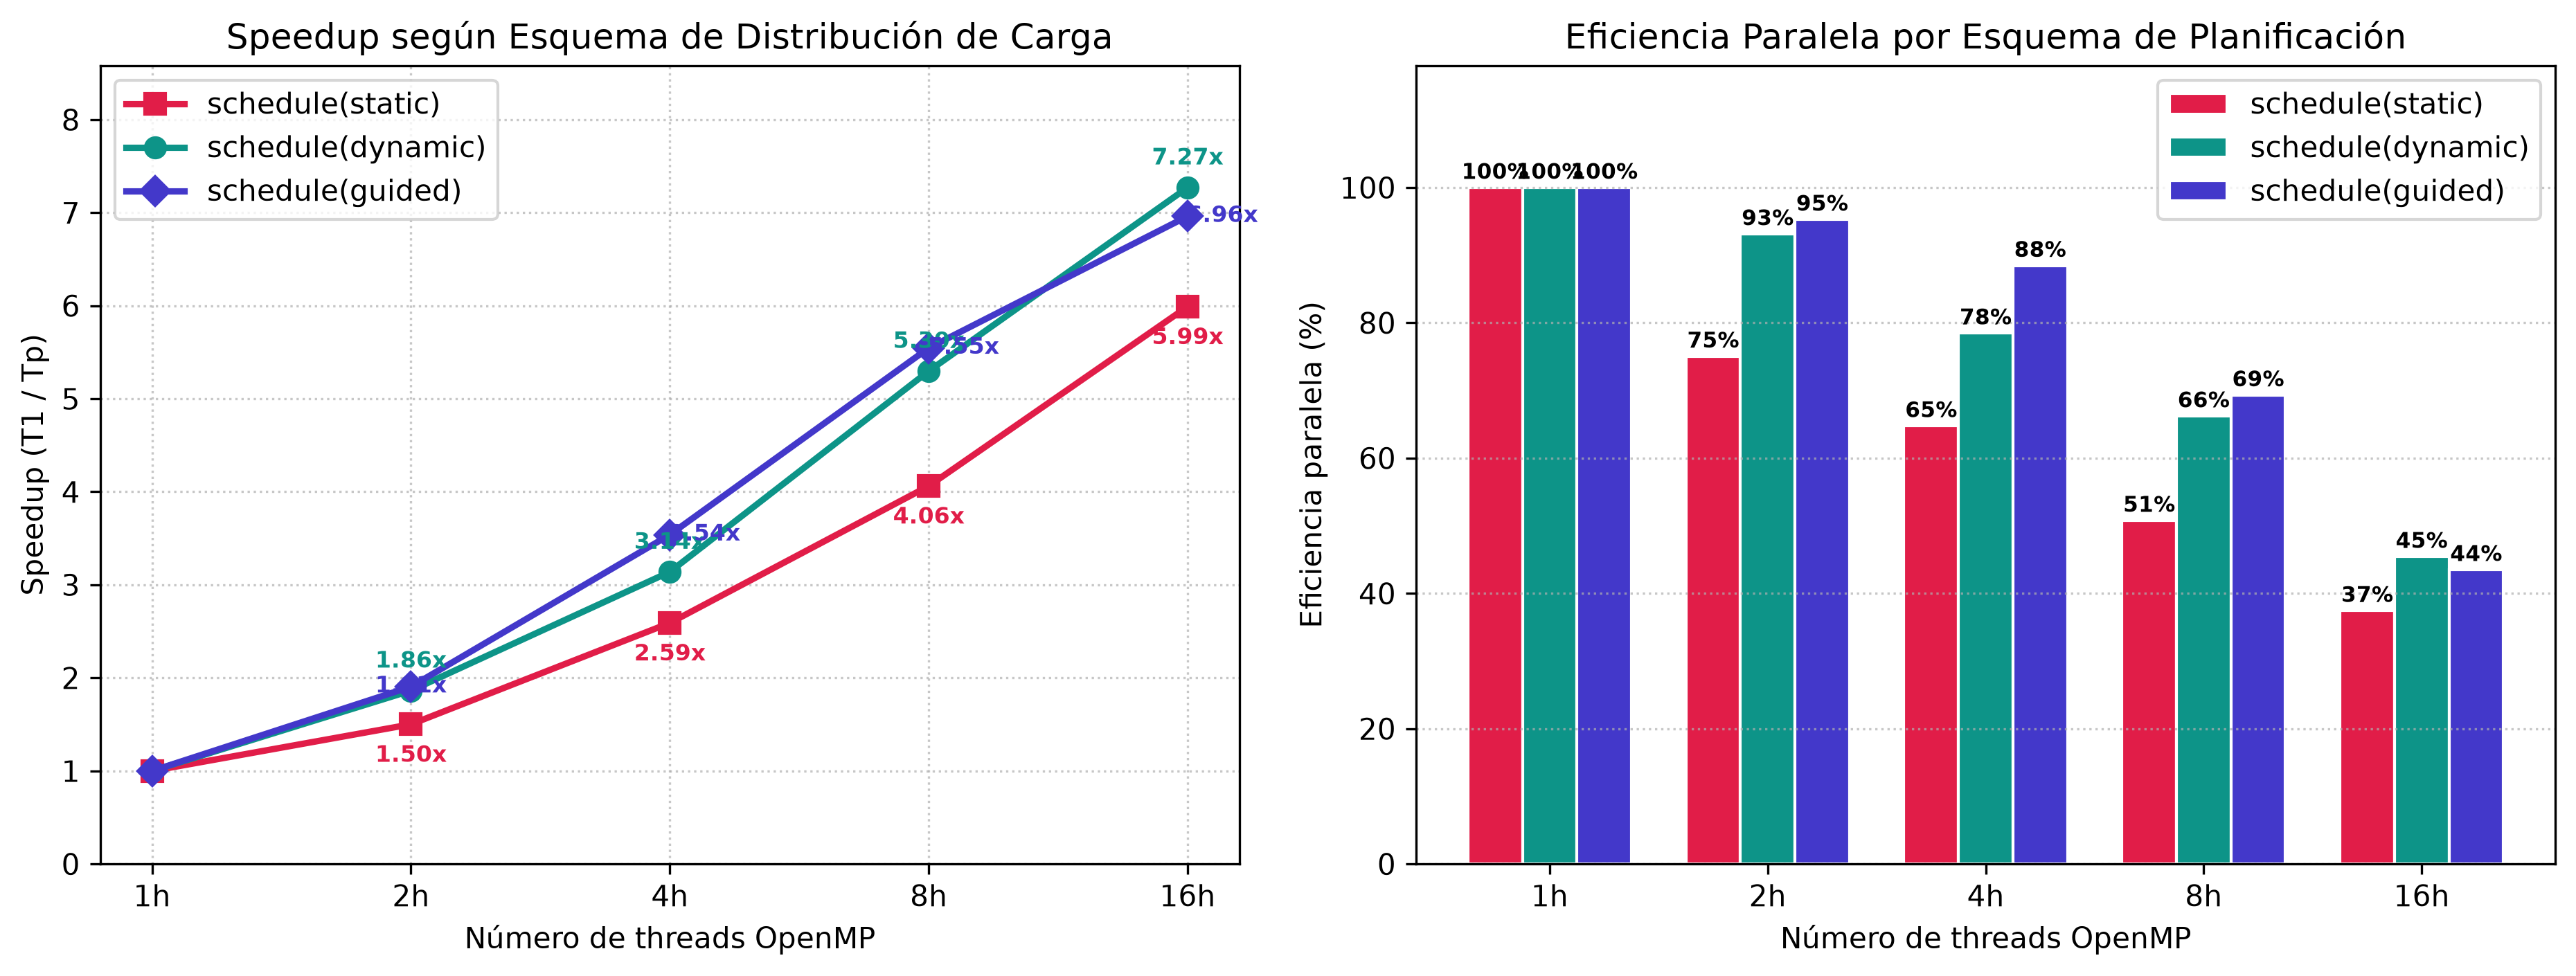

In [3]:
hilos = sorted(df['threads'].unique())
etiquetas_h = [f'{t}h' for t in hilos]
x = np.arange(len(hilos))

esquemas = ['static', 'dynamic', 'guided']
colores = {'static': '#e11d48', 'dynamic': '#0d9488', 'guided': '#4338ca'}
marcadores = {'static': 's', 'dynamic': 'o', 'guided': 'D'}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=300)

# Panel izquierdo: Speedup por esquema de planificación
for esq in esquemas:
    sub = df[df['schedule'] == esq].sort_values('threads')
    sp = sub['speedup'].to_numpy()
    ax1.plot(x, sp, marker=marcadores[esq], markersize=7, linewidth=2.2, color=colores[esq], label=f'schedule({esq})')
    for xi, yi in zip(x, sp):
        if xi > 0:
            dy = -13 if esq == 'static' else (8 if esq == 'dynamic' else -2)
            dx = 12 if (esq == 'guided' and xi >= 2) else 0
            ax1.annotate(f'{yi:.2f}x', (xi, yi), xytext=(dx, dy), textcoords='offset points',
                         ha='center', fontsize=8, color=colores[esq], fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas_h)
ax1.set_ylim(0, max(df['speedup']) * 1.18)
ax1.set_xlabel('Número de threads OpenMP')
ax1.set_ylabel('Speedup (T1 / Tp)')
ax1.set_title('Speedup según Esquema de Distribución de Carga')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle=':', alpha=0.7)

# Panel derecho: Barras agrupadas de Eficiencia (%)
ancho = 0.25
desp = {'static': -ancho, 'dynamic': 0.0, 'guided': ancho}

for esq in esquemas:
    sub = df[df['schedule'] == esq].sort_values('threads')
    ef = sub['eficiencia_pct'].to_numpy()
    barras = ax2.bar(x + desp[esq], ef, width=ancho, color=colores[esq], edgecolor='white', label=f'schedule({esq})')
    for b in barras:
        h = b.get_height()
        ax2.annotate(f'{h:.0f}%', (b.get_x() + b.get_width() / 2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', fontsize=7.5, fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas_h)
ax2.set_ylim(0, 118)
ax2.set_xlabel('Número de threads OpenMP')
ax2.set_ylabel('Eficiencia paralela (%)')
ax2.set_title('Eficiencia Paralela por Esquema de Planificación')
ax2.legend(loc='upper right')
ax2.grid(True, axis='y', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e2_primos_schedules_omp.png', dpi=300)
plt.show()